<a href="https://colab.research.google.com/github/rlaj0730-design/Text-Mining/blob/main/ex02_%EC%83%81%ED%92%88_%EB%A6%AC%EB%B7%B0_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EA%B0%90%EC%84%B1_%EB%B6%84%EC%84%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 구글 드라이브 마운트
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 작업 경로 변경
%cd /content/drive/MyDrive/Colab Notebooks/동아 텍스트마이닝

/content/drive/MyDrive/Colab Notebooks/동아 텍스트마이닝


In [ ]:
# 라이브러리 불러오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

In [ ]:
# 한글 글꼴 설치
!apt-get install -y fonts-nanum*
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'fonts-nanum-extra' for glob 'fonts-nanum*'
Note, selecting 'fonts-nanum-coding' for glob 'fonts-nanum*'
Note, selecting 'fonts-nanum-eco' for glob 'fonts-nanum*'
Note, selecting 'fonts-nanum' for glob 'fonts-nanum*'
fonts-nanum is already the newest version (20200506-1).
fonts-nanum-coding is already the newest version (2.5-3).
fonts-nanum-eco is already the newest version (1.000-7).
fonts-nanum-extra is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/font

### 실습 파일 불러오기
- naver_shopping.txt 파일 df로 불러오기 → data
- \t으로 데이터 구분 되어있음

In [ ]:
data = pd.read_csv("./data/naver_shopping.txt", delimiter="\t", header = None)
# read_csv 함수는 맨 첫번째 줄을 header로 인식 -> 컬럼 이름으로 넣음
data

,0,1
0,5,배공빠르고 굿
1,2,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...
3,2,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...
4,5,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ
...,...,...
199995,2,장마라그런가!!! 달지않아요
199996,5,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...
199997,5,로드샾에서 사는것보다 세배 저렴하네요 ㅜㅜ 자주이용할께요
199998,5,넘이쁘고 쎄련되보이네요~


In [ ]:
# 컬럼명 업데이트
data.columns = ["평점", "리뷰"]
data

,평점,리뷰
0,5,배공빠르고 굿
1,2,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...
3,2,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...
4,5,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ
...,...,...
199995,2,장마라그런가!!! 달지않아요
199996,5,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...
199997,5,로드샾에서 사는것보다 세배 저렴하네요 ㅜㅜ 자주이용할께요
199998,5,넘이쁘고 쎄련되보이네요~


In [ ]:
# 필요한 리뷰 데이터만 인덱싱
text = data["리뷰"]
text

,리뷰
0,배공빠르고 굿
1,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고
2,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...
3,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...
4,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ
...,...
199995,장마라그런가!!! 달지않아요
199996,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...
199997,로드샾에서 사는것보다 세배 저렴하네요 ㅜㅜ 자주이용할께요
199998,넘이쁘고 쎄련되보이네요~


### 텍스트 데이터 전처리
1. 결측치 확인
2. 특수문자 제거

In [ ]:
# 결측치 확인
data.info()
# 결측치는 없음!

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   평점      200000 non-null  int64 
 1   리뷰      200000 non-null  object
dtypes: int64(1), object(1)
memory usage: 3.1+ MB


In [ ]:
# re모듈을 활용해 특수문자 제거
import re # 정규표현식을 사용하기 위한 모듈

##### 정규표현식(Regular Expression)
- 특정한 패턴(규칙)을 가진 문자열의 집합을 표현하는 언어
- 핸드폰번호나 이메일처럼 패턴이 있는 문자열의 검색과 치환을 위해 프로그래밍 언어에서 대부분 지원
- https://wikidocs.net/21703

| 특수 문자        | 설명                                                                 |
|------------------|----------------------------------------------------------------------|
| `.`              | 한 개의 임의의 문자 (단, 줄바꿈 문자 `\n` 제외)                       |
| `?`              | 앞의 문자가 **있을 수도, 없을 수도** 있음 (0개 또는 1개)             |
| `*`              | 앞의 문자가 **0개 이상** 반복됨                                       |
| `+`              | 앞의 문자가 **1개 이상** 반복됨                                       |
| `^`              | **문자열의 시작**을 의미                                              |
| `$`              | **문자열의 끝**을 의미                                                |
| `{숫자}`         | 정확히 해당 **숫자만큼 반복**함                                       |
| `{숫자1, 숫자2}` | **숫자1 이상 숫자2 이하** 만큼 반복함                                 |
| `{숫자,}`        | **숫자 이상** 반복함                                                  |
| `[...]`          | 대괄호 안의 문자들 중 **하나**와 매치. 예: `[abc]` → a 또는 b 또는 c |
| `[a-z]`          | **소문자 알파벳 범위**와 매치                                         |
| `[a-zA-Z]`       | **모든 알파벳**과 매치                                                |
| `[^문자]`        | **해당 문자를 제외한 문자**와 매치                                    |


In [ ]:
# 전화번호를 추출
# 010-1234-5678 / 01012345678 / 010-12345678
# 중간에 하이픈이 있거나 없거나 하는 모든 패턴을 추출

# 정규표현식을 사용해 규칙 생성
p = re.compile("010-?[0-9]{4}-?[0-9]{4}")
# ? : 앞에 있는 문자가 있을수도 있고 없을수도 있다(1개 or 0개)
# [] : 대괄호 안의 문자 하나와 매칭
# {숫자} : 앞에 있는 문자가 숫자만큼 반복

In [ ]:
# 생성한 규칙을 가지고 문자 패턴 검색
result = p.search("내 전화번호는 010-1234-5678이야!")

In [ ]:
print(result)
# span : (시작점, 끝점+1)
# match : 정해진 규칙과 일치하는 부분

<re.Match object; span=(8, 21), match='010-1234-5678'>


In [ ]:
str1 = "내 전화번호는 010-1234-5678이야!"
str1[result.start():result.end()]

'010-1234-5678'

In [ ]:
# 리뷰 데이터에 특수문자 제거
# 영어 소문자, 영어 대문자, 숫자, 한글, 띄어쓰기, 온점(.), 물음표(?), 느낌표(!) 제외한 문자 제거

# 패턴 저장
pattern = r"[^a-zA-Z0-9가-힣\s\.\?\!]"

# r : '\'를 파이썬이 특수문자로 해석하지 않고 문자 그대로 처리하도록 함
# ^ : not
# a-z : 영어 소문자
# A-Z : 영어 대문자
# 가-힣 : 한글
# \s : 띄어쓰기, \. : 온점, \? : 물음표, \! : 느낌표

In [ ]:
# 반복문을 통해 데이터에 모두 패턴 적용
from tqdm import tqdm
# 반복문의 진행 상황을 bar 형태로 보여주는 기능

new_doc = []
for doc in tqdm(text) :
  clean_doc = re.sub(pattern,"",doc)
  # re.sub(패턴, 바꿀 문자열, 원본 문자열)
  # 패턴에 해당하는 부분을 바꿔줌
  new_doc.append(clean_doc)

100%|██████████| 200000/200000 [00:00<00:00, 320489.52it/s]


In [ ]:
# 정제된 텍스트 데이터를 새로운 컬럼으로 추가
data["cleaned_doc"] = new_doc

In [ ]:
data

,평점,리뷰,cleaned_doc
0,5,배공빠르고 굿,배공빠르고 굿
1,2,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...
3,2,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...
4,5,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요
...,...,...,...
199995,2,장마라그런가!!! 달지않아요,장마라그런가!!! 달지않아요
199996,5,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...
199997,5,로드샾에서 사는것보다 세배 저렴하네요 ㅜㅜ 자주이용할께요,로드샾에서 사는것보다 세배 저렴하네요 자주이용할께요
199998,5,넘이쁘고 쎄련되보이네요~,넘이쁘고 쎄련되보이네요


In [ ]:
# 이모지 제거
!pip install emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 5.6 MB/s eta 0:00:00


In [ ]:
temp = "DM으로 연락해주세요🙏🙏😊😘😒"

In [ ]:
import emoji

In [ ]:
emoji.demojize(temp)
# 이모지를 해석해서 문자열로 반환

'DM으로 연락해주세요:folded_hands::folded_hands::smiling_face_with_smiling_eyes::face_blowing_a_kiss::unamused_face:'

In [ ]:
emoji.replace_emoji(temp)
# 문자열에 포함된 이모지를 빈 문자열로 대체하여 제거

'DM으로 연락해주세요'

In [ ]:
emoji.replace_emoji(temp).strip()
# 문자열 양쪽 끝의 공백 및 줄바꿈 문자 제거

'DM으로 연락해주세요'

### 형태소 분리
- 형태소 분리, 어간추출, 정규화, 원하는 품사 추출, 불용어 제거, 띄어쓰기 교정
- DF 새로운 컬럼으로 추가

In [ ]:
# konlpy -> Okt, Kkma
# kiwipiepy -> Kiwi

# Kiwi -> 불용어 제거, 띄어쓰기 교정
# Okt -> 형태소 분석

In [ ]:
!pip install kiwipiepy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 6.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 44.4 MB/s eta 0:00:00
  Created wheel for kiwipiepy_model: filename=kiwipiepy_model-0.24.0-py3-none-any.whl size=87973829 sha256=9bcdcfa285eb7c77f7566c2644cd228dc91d2601393ff2449fc38ed2d9ba727c
  Stored in directory: /root/.cache/pip/wheels/1e/08/d4/4ff00b71c6b738e5308a0867385c986a743e5307c5206da985
Successfully built kiwipiepy_model


In [ ]:
# 불용어 사전 로드
from kiwipiepy.utils import Stopwords

In [ ]:
# 불용어 사전 객체 초기화
stopwords = Stopwords()

In [ ]:
stopwords.stopwords

{('ᆫ', 'ETM'),
 ('ᆫ', 'JX'),
 ('ᆫ다', 'EF'),
 ('ᆯ', 'ETM'),
 ('가', 'JKS'),
 ('같', 'VA'),
 ('것', 'NNB'),
 ('게', 'EC'),
 ('겠', 'EP'),
 ('고', 'EC'),
 ('고', 'JKQ'),
 ('과', 'JC'),
 ('과', 'JKB'),
 ('그', 'MM'),
 ('그', 'NP'),
 ('기', 'ETN'),
 ('까지', 'JX'),
 ('나', 'NP'),
 ('년', 'NNB'),
 ('는', 'ETM'),
 ('는', 'JX'),
 ('다', 'EC'),
 ('다', 'EF'),
 ('다고', 'EC'),
 ('다는', 'ETM'),
 ('대하', 'VV'),
 ('더', 'MAG'),
 ('던', 'ETM'),
 ('도', 'JX'),
 ('되', 'VV'),
 ('되', 'XSV'),
 ('들', 'XSN'),
 ('등', 'NNB'),
 ('따르', 'VV'),
 ('때', 'NNG'),
 ('때문', 'NNB'),
 ('라', 'EC'),
 ('라는', 'ETM'),
 ('로', 'JKB'),
 ('를', 'JKO'),
 ('만', 'JX'),
 ('만', 'NR'),
 ('말', 'NNG'),
 ('며', 'EC'),
 ('면', 'EC'),
 ('면서', 'EC'),
 ('명', 'NNB'),
 ('받', 'VV'),
 ('보', 'VV'),
 ('부터', 'JX'),
 ('사람', 'NNG'),
 ('성', 'XSN'),
 ('수', 'NNB'),
 ('아니', 'VCN'),
 ('않', 'VX'),
 ('어', 'EC'),
 ('어', 'EF'),
 ('어서', 'EC'),
 ('어야', 'EC'),
 ('없', 'VA'),
 ('었', 'EP'),
 ('에', 'JKB'),
 ('에게', 'JKB'),
 ('에서', 'JKB'),
 ('와', 'JC'),
 ('와', 'JKB'),
 ('우리', 'NP'),
 ('원', 'NNB'),


In [ ]:
# 키위의 불용어 리스트는 단어, 품사가 들어가 있는데
# 여기서 단어들만 추출해보자

# stopwords_list = []
# for word, tag in stopwords.stopwords :
#   stopwords_list.append(word)

# 리스트 컴프리헨션(List Comprehension)
# for문을 사용해 리스트를 만드는 과정을 한줄로 간단하게 표현하는 문법

stopwords_list = [word for word, tag in stopwords.stopwords]

stopwords_list

['주',
 '라는',
 '말',
 '그',
 '라',
 '이',
 '들',
 '지만',
 '는',
 '다',
 '으로',
 '않',
 '과',
 '과',
 '같',
 '게',
 '기',
 'ᆫ',
 '어',
 '와',
 '따르',
 '제',
 '되',
 '대하',
 '등',
 '부터',
 '없',
 '있',
 '통하',
 'ᆫ다',
 '만',
 '도',
 '에게',
 '이',
 '일',
 '지',
 '이',
 '적',
 '었',
 '되',
 '어야',
 '있',
 '는',
 '면서',
 '다',
 '명',
 '하',
 '던',
 '만',
 '고',
 '화',
 '에',
 '에서',
 '을',
 '한',
 'ᆯ',
 '나',
 '때문',
 '와',
 '며',
 '을',
 '원',
 '우리',
 '지',
 '이',
 '일',
 '지역',
 '더',
 '하',
 '이',
 '사람',
 '아니',
 '보',
 '위하',
 '성',
 '하',
 '때',
 '로',
 '은',
 '년',
 '가',
 '다는',
 '것',
 '고',
 '겠',
 '어서',
 '다고',
 '어',
 'ᆫ',
 '하',
 '중',
 '받',
 '를',
 '수',
 '까지',
 '그',
 '의',
 '면',
 '은',
 '월']

In [ ]:
!pip install konlpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 438.5/438.5 kB 12.9 MB/s eta 0:00:00


In [ ]:
# 형태소 분석기 객체 초기화
from konlpy.tag import Okt
from kiwipiepy import Kiwi

okt = Okt()
kiwi = Kiwi()

In [ ]:
# kiwi -> 띄어쓰기 교정
# okt -> 형태소 분리, 어간 추출, 정규화, 원하는 품사 필터링

# 위 과정을 한 번에 진행할 수 있는 함수 정의

def pos_tagging(text) :
  # 1. 띄어쓰기 교정
  text = kiwi.space(text)

  # 2. 형태소 분리
  pos_words = okt.pos(
      text,
      norm = True, # 정규화 : 비표준 문어체를 표준어로 정규화
      stem = True, # 어간 추출 : 들어가있는 단어를 기본형으로 복원
  )

  # 3. 원하는 품사만 추출(명사, 동사, 형용사)
  # + 불용어 리스트에 해당하지 않는지도 확인
  tagged_list = []

  for word, tag in pos_words :
    if tag in ["Noun", "Verb", "Adjective"] :
      if word not in stopwords_list :
        tagged_list.append(word)

  return tagged_list

In [ ]:
# 함수 작동 테스트
pos_tagging(data["cleaned_doc"][2])

['아주',
 '좋다',
 '바지',
 '정말',
 '좋다',
 '개',
 '구매',
 '하다',
 '가격',
 '대박',
 '이다',
 '바느질',
 '조금',
 '성하다',
 '편하다',
 '가성',
 '비',
 '최고']

In [ ]:
# 전체 데이터에 적용
tagged_doc = []
for text in tqdm(data["cleaned_doc"]):
  tagged_doc.append(pos_tagging(text))

100%|██████████| 200000/200000 [23:37<00:00, 141.10it/s]


In [ ]:
# data에 새로운 컬럼으로 추가
data["tagged_doc"] = tagged_doc

In [ ]:
data

,평점,리뷰,cleaned_doc,tagged_doc
0,5,배공빠르고 굿,배공빠르고 굿,"[배공, 빠르다, 굿]"
1,2,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고,"[택배, 엉망, 용, 저희, 집, 밑, 층, 놔두다, 가다]"
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...,"[아주, 좋다, 바지, 정말, 좋다, 개, 구매, 하다, 가격, 대박, 이다, 바느..."
3,2,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...,"[선물, 용, 받다, 전달, 하다, 하다, 상품, 이다, 데, 머그, 컵, 오다, ..."
4,5,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요,"[민트, 색상, 예쁘다, 옆, 손잡이, 거, 용, 도로, 사용, 되다]"
...,...,...,...,...
199995,2,장마라그런가!!! 달지않아요,장마라그런가!!! 달지않아요,"[장마, 런가, 달, 않다]"
199996,5,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...,"[다이슨, 케이스, 구매, 하다, 다이슨, 슈퍼, 소닉, 드라이기, 케이스, 구매,..."
199997,5,로드샾에서 사는것보다 세배 저렴하네요 ㅜㅜ 자주이용할께요,로드샾에서 사는것보다 세배 저렴하네요 자주이용할께요,"[로드샾, 살다, 세, 배, 저렴하다, 자주, 이용, 하다]"
199998,5,넘이쁘고 쎄련되보이네요~,넘이쁘고 쎄련되보이네요,"[넘다, 이쁘다, 쎄다, 되다, 보이다]"


In [ ]:
# 전처리 과정이 오래걸렸기 때문에 현재까지의 결과를 한 번 저장해서
# 세션을 다시 시작하더라도 바로 불러올 수 있도록 하는 방법

# 전처리가 완료된 데이터를 파일로 저장
# pickle : 파이썬 객체(리스트, 딕셔너리, 데이터프레임 등)를 파일로 저장하고 불러오는 라이브러리
import pickle

with open("./data/naver_shopping(정제 및 토큰화 완료).pkl", "wb") as f :
  pickle.dump(data, f) # 데이터를 파일에 저장

In [ ]:
# pkl 파일 불러오기
with open("./data/naver_shopping(정제 및 토큰화 완료).pkl", "rb") as f :
  data = pickle.load(f)

In [ ]:
data

,평점,리뷰,cleaned_doc,tagged_doc
0,5,배공빠르고 굿,배공빠르고 굿,"[배공, 빠르다, 굿]"
1,2,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고,"[택배, 엉망, 용, 저희, 집, 밑, 층, 놔두다, 가다]"
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...,"[아주, 좋다, 바지, 정말, 좋다, 개, 구매, 하다, 가격, 대박, 이다, 바느..."
3,2,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...,"[선물, 용, 받다, 전달, 하다, 하다, 상품, 이다, 데, 머그, 컵, 오다, ..."
4,5,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요,"[민트, 색상, 예쁘다, 옆, 손잡이, 거, 용, 도로, 사용, 되다]"
...,...,...,...,...
199995,2,장마라그런가!!! 달지않아요,장마라그런가!!! 달지않아요,"[장마, 런가, 달, 않다]"
199996,5,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...,"[다이슨, 케이스, 구매, 하다, 다이슨, 슈퍼, 소닉, 드라이기, 케이스, 구매,..."
199997,5,로드샾에서 사는것보다 세배 저렴하네요 ㅜㅜ 자주이용할께요,로드샾에서 사는것보다 세배 저렴하네요 자주이용할께요,"[로드샾, 살다, 세, 배, 저렴하다, 자주, 이용, 하다]"
199998,5,넘이쁘고 쎄련되보이네요~,넘이쁘고 쎄련되보이네요,"[넘다, 이쁘다, 쎄다, 되다, 보이다]"


### Word2Vec
- 단어 임베딩 모델 중 하나
- 컴퓨터가 단어와 단어의 의미 사이의 관계를 학습할 수 있도록 단어를 숫자로 표현하는 방법

> 두가지 방법
> 1. CBOW : 주변에 있는 단어들을 입력으로 중간에 있는 단어들을 학습/예측하는 방법
> 2. Skip-gram : 중간에 있는 단어들을 입력으로 주변 단어들을 학습/예측하는 방법


### 예시
**원본 문장**
> 나는 맛있는 사과를 먹었다.

**단어 벡터**

단어를 3차원 벡터로 표현한다고 가정하면,

| 단어 | 학습 전 벡터(임의의 숫자) |
|---|---|
| 사과 | [0.2, -0.5, 0.1] |
| 바나나 | [-0.8, 0.3, 0.6] |
| 자동차 | [0.4, 0.1, -0.7] |

처음에는 각 숫자에 특별한 의미가 없지만, 학습을 반복하면서 주변 문맥의 패턴이 벡터에 반영됨

---

### CBOW

중심 단어를 '사과를'이라고 가정하면 다음과 같이 학습함

- **입력(주변 단어)** : 나는, 맛있는, 먹었다
- **정답(중심 단어)** : 사과를
- **학습 과정** : 주변 단어를 바탕으로 중심 단어를 예측하고, 정답과의 차이를 줄이도록 모델 내부의 가중치를 수정

### CBOW의 전체 학습 과정

**STEP 1. 단어 벡터 초기화**
- 각 단어에 임의의 숫자 벡터를 부여

**STEP 2. 중심 단어 예측**
- 주변 단어들의 벡터를 이용하여 중심 단어 예측

**STEP 3. 예측 오차를 줄이도록 학습**
- 예측 결과와 실제 중심 단어를 비교
- 예측이 더 정확해지도록 단어 벡터를 포함한 모델 내부 가중치 수정

**STEP 4. 학습된 단어 벡터 획득**
- 학습을 반복하면서 단어의 문맥적 특성이 반영된 벡터 생성
- 학습이 완료되면 각 단어를 숫자 벡터로 표현할 수 있음

---
### Skip-gram

중심 단어를 '사과를'이라고 가정하면 다음과 같이 학습함.

- **입력(중심 단어)** : 사과를
- **정답(주변 단어)** : 나는, 맛있는, 먹었다
- **학습 과정** : 중심 단어를 바탕으로 주변 단어들을 예측하고, 정답을 더 잘 예측하도록 모델 내부의 가중치를 수정

### Skip-gram의 전체 학습 과정

**STEP 1. 단어 벡터 초기화**
- 각 단어에 임의의 숫자 벡터를 부여

**STEP 2. 주변 단어 예측**
- 중심 단어의 벡터를 이용하여 주변에 등장할 단어 예측
- 예를 들어 '사과를'이라는 중심 단어로 '맛있는', '먹었다' 등의 주변 단어 예측

**STEP 3. 예측 오차를 줄이도록 학습**
- 예측 결과와 실제 주변 단어를 비교
- 주변 단어를 더 잘 예측하도록 단어 벡터를 포함한 모델 내부 가중치 수정

**STEP 4. 학습된 단어 벡터 획득**
- 학습을 반복하면서 단어의 문맥적 특성이 반영된 벡터 생성
- 학습이 완료되면 각 단어를 숫자 벡터로 표현할 수 있음

In [ ]:
# gensim : Word2Vec, Doc2Vec 등 단어 임베딩 모델을 다루는 라이브러리
!pip install gensim

In [ ]:
# 사전학습된 모델이나 데이터셋을 다운로드하는 모듈
import gensim.downloader as api

In [ ]:
# Gensim에서 제공하는 사전 학습된 모델들의 목록을 가져와서,
# 각 모델의 이름과 데이터 개수, 설명을 출력

# 'api.info()' 메서드를 통해 모델들의 정보를 가져와서
# 'models'라는 키 아래에 있는 항목들을 정렬하여 반복
for model_name, model_data in sorted(api.info()['models'].items()): # 모델 목록을 이름순으로 정렬한 뒤 하나씩 꺼내기

    # 각 모델의 데이터에서 'num_records' 키에 해당하는 값이 있으면 사용, 없으면 기본값 -1을 사용
    num_records = model_data.get('num_records', -1)

    # 각 모델의 설명을 40자까지만 잘라서 표시하고 그 뒤에 '...'을 추가
    description = model_data['description'][:40] + '...'

    # 각 모델의 이름, 레코드 수, 그리고 잘린 설명을 출력
    print(f"{model_name} ({num_records} records): {description}")

__testing_word2vec-matrix-synopsis (-1 records): [THIS IS ONLY FOR TESTING] Word vecrors ...
conceptnet-numberbatch-17-06-300 (1917247 records): ConceptNet Numberbatch consists of state...
fasttext-wiki-news-subwords-300 (999999 records): 1 million word vectors trained on Wikipe...
glove-twitter-100 (1193514 records): Pre-trained vectors based on  2B tweets,...
glove-twitter-200 (1193514 records): Pre-trained vectors based on 2B tweets, ...
glove-twitter-25 (1193514 records): Pre-trained vectors based on 2B tweets, ...
glove-twitter-50 (1193514 records): Pre-trained vectors based on 2B tweets, ...
glove-wiki-gigaword-100 (400000 records): Pre-trained vectors based on Wikipedia 2...
glove-wiki-gigaword-200 (400000 records): Pre-trained vectors based on Wikipedia 2...
glove-wiki-gigaword-300 (400000 records): Pre-trained vectors based on Wikipedia 2...
glove-wiki-gigaword-50 (400000 records): Pre-trained vectors based on Wikipedia 2...
word2vec-google-news-300 (3000000 records): Pre-trai

- Records : 레코드의 수, 즉 데이터의 개수를 의미(각 "레코드"는 임베딩된 단어 하나를 의미)

| 모델 이름                           | 레코드 수      | 설명                                                                                                  |
|-------------------------------------|----------------|-------------------------------------------------------------------------------------------------------|
| conceptnet-numberbatch-17-06-300    | 1,917,247      | ConceptNet Numberbatch는 개념 간의 관계를 학습한 모델.                                                 |
|                                     |                | 상식을 이해하고 개념 간 관계를 연결시키기 위해 개발됨.                                                 |
|                                     |                | 주로 의미 네트워크 연구에 사용됨. "고양이"와 "동물" 간의 관계를 학습.                                  |
| fasttext-wiki-news-subwords-300     | 999,999        | fastText는 단어뿐만 아니라 서브워드(단어의 작은 부분)를 학습.                                          |
|                                     |                | "unbelievable"을 "un", "believe", "able"로 나누어 학습.                                                 |
|                                     |                | Wikipedia와 뉴스 기사 데이터를 기반으로 학습됨.                                                       |
| glove-twitter-100                   | 1,193,514      | GloVe는 Stanford에서 개발된 모델로, 단어 간의 공간적 관계를 벡터로 표현.                               |
|                                     |                | 트위터 데이터(2억 개 트윗)로 학습되어 소셜 미디어 자연어 처리 작업에 적합.                             |
| word2vec-google-news-300            | 3,000,000      | Word2Vec은 구글 뉴스 데이터로 학습된 모델.                                                             |
|                                     |                | 뉴스 기사의 단어 간 유사성 및 의미적 관계를 잘 포착.                                                   |
|                                     |                | 뉴스 데이터 기반이기 때문에 자연어 처리에 많이 사용됨.                                                 |
| word2vec-ruscorpora-300             | 184,973        | Word2Vec ruscorpora는 러시아어 텍스트 기반의 모델로,                                                   |
|                                     |                | 러시아어 자연어 처리 작업에 사용됨.                                                                   |


In [ ]:
# word2vec-google-news-300
# 구글 뉴스데이터로 훈련된 word2vec 모델
# 300만개의 단어 벡터를 포함하고 있으며 각 단어는 300차원의 벡터로 표현
model = api.load("word2vec-google-news-300")

In [ ]:
# 'cat' 단어의 임베딩 벡터를 가져와보자
cat_vector = model["cat"]
cat_vector

array([ 0.0123291 ,  0.20410156, -0.28515625,  0.21679688,  0.11816406,
        0.08300781,  0.04980469, -0.00952148,  0.22070312, -0.12597656,
        0.08056641, -0.5859375 , -0.00445557, -0.296875  , -0.01312256,
       -0.08349609,  0.05053711,  0.15136719, -0.44921875, -0.0135498 ,
        0.21484375, -0.14746094,  0.22460938, -0.125     , -0.09716797,
        0.24902344, -0.2890625 ,  0.36523438,  0.41210938, -0.0859375 ,
       -0.07861328, -0.19726562, -0.09082031, -0.14160156, -0.10253906,
        0.13085938, -0.00346375,  0.07226562,  0.04418945,  0.34570312,
        0.07470703, -0.11230469,  0.06738281,  0.11230469,  0.01977539,
       -0.12353516,  0.20996094, -0.07226562, -0.02783203,  0.05541992,
       -0.33398438,  0.08544922,  0.34375   ,  0.13964844,  0.04931641,
       -0.13476562,  0.16308594, -0.37304688,  0.39648438,  0.10693359,
        0.22167969,  0.21289062, -0.08984375,  0.20703125,  0.08935547,
       -0.08251953,  0.05957031,  0.10205078, -0.19238281, -0.09

## 유사도 계산
- 유사도(Similarity) : 비슷한 정도

> 1. Euclidean Distance(유클리디안 거리) : 두 데이터 사이의 실제 거리가 얼마나 가까운가?
> 2. Cosine Similarity(코사인 유사도) : 두 데이터의 벡터가 얼마나 비슷한 방향을 가리키는가?
> - 유클리디안 거리에서는 `거리가 가까울 수록`, 코사인 유사도에서는 `각 데이터 간의 각도가 작을 수록` 데이터가 비슷하다는 것을 의미

### 코사인 유사도

$ similarity=cos(Θ)=\frac{A⋅B}{||A||\ ||B||}=\frac{\sum_{i=1}^{n}{A_{i}×B_{i}}}{\sqrt{\sum_{i=1}^{n}(A_{i})^2}×\sqrt{\sum_{i=1}^{n}(B_{i})^2}} $

> **분자(위쪽 식):**  
> - $(A \cdot B)$ : 두 벡터의 내적(점곱)  
> - $(\sum_{i=1}^n A_i \times B_i$) 형태로 각 차원별 곱을 모두 더한 값  

> **분모(아래쪽 식):**  
> - $(\|A\|$)와 $(\|B\|$)는 각각 벡터 $(A$)와 $(B$)의 크기(놈, norm)  
> - $(\sqrt{\sum_{i=1}^n (A_i)^2}$)와 $(\sqrt{\sum_{i=1}^n (B_i)^2}$)로 계산  


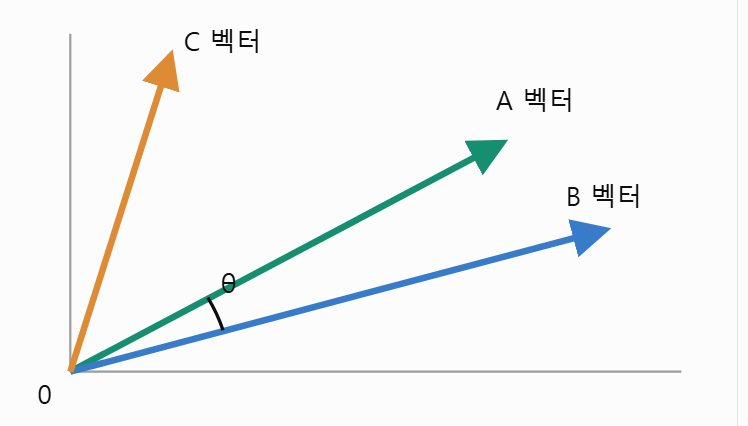

<img src = "https://static.wikidocs.net/images/page/24603/%EC%BD%94%EC%82%AC%EC%9D%B8%EC%9C%A0%EC%82%AC%EB%8F%84.PNG"/>



> **결과 해석:**  
> - 두 벡터가 완전히 동일한 방향이면(각도 $(\theta = 0$)) 유사도는 1  
> - 두 벡터가 서로 직교(각도 $(90^\circ$))하면 유사도는 0  
> - 두 벡터가 반대 방향이면(각도 $(\theta = 180^\circ$)) 유사도는 -1  
> - 코사인 유사도는 -1부터 1까지의 값을 가지며, 1에 가까울수록 유사도가 높고 -1에 가까울수록 유사도가 낮다고 해석함


In [ ]:
# 유사도를 계산하여 'cat'이라는 단어와 가장 가까운 단어들을 나열
# most_similar() : 기본적으로 코사인 유사도를 사용하여 단어 간 유사도를 계산
model.most_similar("cat")

# 코사인 유사도 -1~1 사이의 값
# 두 벡터의 코사인 유사도 값이 1에 가까울수록 유사도가 높은 단어라고 판단

[('cats', 0.8099379539489746),
 ('dog', 0.760945737361908),
 ('kitten', 0.7464985251426697),
 ('feline', 0.7326234579086304),
 ('beagle', 0.7150582671165466),
 ('puppy', 0.7075453400611877),
 ('pup', 0.6934291124343872),
 ('pet', 0.6891531348228455),
 ('felines', 0.6755931973457336),
 ('chihuahua', 0.6709762215614319)]

In [ ]:
# most_similar_cosmul() : 입력한 단어들과의 유사도를 계산하여 가장 적합한 단어들을 반환하는 함수
# positive : 유사도가 높을수록 점수에 긍정적으로 반영
# negative : 점수에 불리하게 반영
# 여러 단어 사이의 관계를 분석할 때 활용

# 한국과 소주의 관계를 이용해 멕시코와 비슷한 관계에 있는 술을 찾아보기

# 소주와 멕시코에는 관련성이 높지만, 한국과는 상대적으로 관련성이 낮은 단어 찾기
# 소주 : 한국 + 대표 술
# 여기서 대표 술이라는 정보만 남겨두기 위해서 한국과의 관련성을 낮춰줌

model.most_similar_cosmul(positive=["soju", "mexico"], negative=["korea"])

[('tequila', 0.8992794156074524),
 ('mezcal', 0.8555493950843811),
 ('agave_tequila', 0.8524277806282043),
 ('Modelo_Especial', 0.836313784122467),
 ('pulque', 0.8301872611045837),
 ('mescal', 0.8242558240890503),
 ('distilled_liquor', 0.8173635601997375),
 ('Agavero', 0.8148321509361267),
 ('rum', 0.8130227327346802),
 ('michelada', 0.8111985325813293)]

### word2vec 모델 생성해서 직접 학습까지 시켜보기!

In [ ]:
from gensim.models import Word2Vec

In [ ]:
w2v = Word2Vec(
    window = 3, # 한 단어와 관련된 인접한 단어의 범위를 지정
    min_count = 5, # 특정 단어의 최소 등장 횟수
    sg = 1, # CBOW = 0, Skip-gram = 1
    vector_size = 100, # 각 단어를 임베딩할 차원의 수(한 단어를 100개의 숫자를 통해 표현)
    negative = 5, # negative sampling을 몇 개의 단어를 사용할건지
    sentences = data["tagged_doc"] # 학습에 사용할 데이터
)

In [ ]:
# '배송'이라는 단어에 대한 임베딩 벡터 확인
w2v.wv.get_vector('배송')

array([-3.54371637e-01,  1.85212806e-01, -1.88477263e-01, -5.33695579e-01,
       -1.47266746e-01, -6.11231811e-02,  2.48245627e-01,  3.82315159e-01,
       -6.85465336e-02, -2.56114509e-02,  9.70199332e-02,  2.66851842e-01,
        3.24083827e-02, -6.09067120e-02,  4.11626339e-01, -7.87281990e-01,
       -1.84440523e-01, -3.00882936e-01, -1.02153882e-01, -2.24118724e-01,
       -3.96977633e-01,  2.90704340e-01,  4.48494643e-01,  2.04186022e-01,
       -1.41245171e-01,  1.72173753e-01, -9.19557810e-02, -3.31237286e-01,
       -3.30551624e-01,  1.20353907e-01, -3.84830832e-02, -5.87795913e-01,
        2.60758787e-01, -7.62266219e-01,  7.59924427e-02,  8.13638985e-01,
        5.57919025e-01,  1.31330192e-01,  2.95799911e-01, -3.34937513e-01,
        4.19320256e-01, -1.84782282e-01, -1.72161639e-01,  4.40088630e-01,
        7.24821687e-02, -2.56239269e-02,  2.37692557e-02, -1.38517663e-01,
        1.97409973e-01,  5.05473316e-02,  2.71651506e-01, -2.79735863e-01,
       -4.20700572e-03,  

In [ ]:
# '만족'과 유사한 단어들을 확인
w2v.wv.most_similar("만족", topn = 20)

[('만족하다', 0.8235541582107544),
 ('만족스럽다', 0.750176727771759),
 ('최상', 0.721938967704773),
 ('민족', 0.7023072242736816),
 ('쿠', 0.6870906352996826),
 ('맘에듬', 0.6865118145942688),
 ('훌륭하다', 0.6832568049430847),
 ('핮니', 0.6722981929779053),
 ('닏', 0.6627182364463806),
 ('강추', 0.6543842554092407),
 ('안성맞춤', 0.6519259214401245),
 ('최강', 0.6489006876945496),
 ('괜차나', 0.6412771344184875),
 ('닷', 0.6406859159469604),
 ('경제', 0.6394733786582947),
 ('쫀쫀합니', 0.6391543745994568),
 ('빨랏구', 0.6384401321411133),
 ('사악하다', 0.6382495164871216),
 ('흐뭇하다', 0.6352561116218567),
 ('젛아', 0.6322183012962341)]

In [ ]:
# '별로'와 유사한 단어들을 확인
w2v.wv.most_similar("별로", topn = 20)

[('별루', 0.7708710432052612),
 ('루', 0.7667886018753052),
 ('꽝', 0.6902822256088257),
 ('벼로', 0.6821529865264893),
 ('그닥', 0.6477909088134766),
 ('별롭니', 0.645808756351471),
 ('루고', 0.6408154368400574),
 ('닥', 0.6231955885887146),
 ('비추다', 0.6162348389625549),
 ('주관', 0.6109360456466675),
 ('의견', 0.6108922958374023),
 ('솔직하다', 0.6057705283164978),
 ('노답', 0.6047440767288208),
 ('형편', 0.6019282937049866),
 ('구림', 0.5972653031349182),
 ('별루임', 0.593263566493988),
 ('구리다', 0.590962827205658),
 ('이상하', 0.5895938873291016),
 ('로예', 0.5893327593803406),
 ('글쎄요', 0.5885592103004456)]

### 평점을 기반으로 긍/부정 분류 + 가중치 분석
1. 평점을 기반으로 라벨 생성(4,5인 경우 1(긍정), 그 외 0(부정))
2. 각 리뷰에 대한 평균 벡터 계산
  - 단어 임베딩 완료
  - 단어가 여러개 모여서 문장 → 1개의 리뷰
  - 문장 안에 들어있는 단어 벡터의 평균을 내서 리뷰 1개를 수치화
3. 로지스틱 회귀 모델링
4. 가중치 시각화



### 평점 기반 라벨 생성

In [ ]:
data["평점"].value_counts()

,count
평점,
5,81177
2,63989
1,36048
4,18786


In [ ]:
# 라벨 붙이기
label = []
for rating in data["평점"] :
  if rating > 3 :
    label.append(1) # 긍정(1) 추가
  else :
    label.append(0) # 부정(0) 추가

In [ ]:
data["label"] = label

In [ ]:
data

,평점,리뷰,cleaned_doc,tagged_doc,label
0,5,배공빠르고 굿,배공빠르고 굿,"[배공, 빠르다, 굿]",1
1,2,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고,"[택배, 엉망, 용, 저희, 집, 밑, 층, 놔두다, 가다]",0
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...,"[아주, 좋다, 바지, 정말, 좋다, 개, 구매, 하다, 가격, 대박, 이다, 바느...",1
3,2,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...,"[선물, 용, 받다, 전달, 하다, 하다, 상품, 이다, 데, 머그, 컵, 오다, ...",0
4,5,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요,"[민트, 색상, 예쁘다, 옆, 손잡이, 거, 용, 도로, 사용, 되다]",1
...,...,...,...,...,...
199995,2,장마라그런가!!! 달지않아요,장마라그런가!!! 달지않아요,"[장마, 런가, 달, 않다]",0
199996,5,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...,다이슨 케이스 구매했어요 다이슨 슈퍼소닉 드라이기 케이스 구매했어요가격 괜찮고 배송...,"[다이슨, 케이스, 구매, 하다, 다이슨, 슈퍼, 소닉, 드라이기, 케이스, 구매,...",1
199997,5,로드샾에서 사는것보다 세배 저렴하네요 ㅜㅜ 자주이용할께요,로드샾에서 사는것보다 세배 저렴하네요 자주이용할께요,"[로드샾, 살다, 세, 배, 저렴하다, 자주, 이용, 하다]",1
199998,5,넘이쁘고 쎄련되보이네요~,넘이쁘고 쎄련되보이네요,"[넘다, 이쁘다, 쎄다, 되다, 보이다]",1


### 리뷰별 평균 벡터 계산

In [ ]:
# 각 리뷰의 평균 벡터값을 담아둘 리스트
X_list = []

In [ ]:
# 평균 벡터 계산
for doc in data["tagged_doc"]:  # 형태소 분석이 완료된 리뷰를 하나씩 가져오기
    vecs = []  # 현재 리뷰에 포함된 단어들의 벡터를 저장할 리스트

    for token in doc:  # 현재 리뷰에 포함된 단어를 하나씩 가져오기
        if token in w2v.wv:  # 해당 단어가 Word2Vec의 학습된 단어 사전에 존재하는지 확인
            vecs.append(w2v.wv[token]) # 단어의 벡터를 가져와 리스트에 추가

    if len(vecs) > 0: # 현재 리뷰에서 벡터를 가져온 단어가 하나 이상 있는 경우
        avg_vec = np.mean(vecs, axis=0)
        # 단어 벡터들의 각 차원별 평균을 계산하여 리뷰 전체를 하나의 벡터로 표현
        # axis=0 : 같은 열(차원)에 있는 숫자끼리 평균 계산

    else: # 현재 리뷰에 Word2Vec 단어 사전에 포함된 단어가 하나도 없는 경우
          # 예: 모든 단어가 min_count=5 조건을 만족하지 못해 제외된 경우
        avg_vec = np.zeros(100)
        # 평균을 계산할 수 없으므로 0으로 채워진 벡터 생성
        # np.zeros(100) → [0., 0., 0., ..., 0.] (100개의 숫자)

    # 현재 리뷰의 평균 벡터를 X_list에 추가
    # 최종적으로 리뷰 하나당 100개의 숫자로 이루어진 벡터가 저장됨
    X_list.append(avg_vec)

In [ ]:
X_list[0:2]

[array([-0.3869288 ,  0.68493986,  0.30323514, -0.13078834, -0.07068853,
        -0.23848878,  0.13954633,  0.34316054, -0.31229287,  0.16116205,
        -0.2791654 , -0.10277498, -0.06632417,  0.14371789, -0.2786016 ,
        -0.05984563,  0.37001616, -0.17800805, -0.10192215, -0.5268217 ,
        -0.34658054,  0.06703733,  0.60916626, -0.12030246, -0.2408976 ,
         0.19498429,  0.0468436 ,  0.02498317,  0.18874085,  0.12278588,
         0.3604579 , -0.83794117,  0.3673694 , -0.39307302, -0.0738122 ,
         0.55647534, -0.21149197,  0.01954815, -0.33953777, -0.3007185 ,
        -0.03646816,  0.0518021 , -0.36110032,  0.24910511,  0.11614116,
         0.31163502, -0.00890372,  0.22191206, -0.0456937 , -0.11469221,
         0.56949526, -0.5961527 ,  0.23269904,  0.09109992, -0.69168824,
         0.32432047,  0.7604252 , -0.21752375, -0.03546093, -0.0363103 ,
         0.0534248 ,  0.08865413,  0.0625921 ,  0.08916181,  0.11515659,
        -0.08308841,  0.4309489 ,  0.24748358, -0.5

In [ ]:
len(X_list)

200000

### 모델링
- Logistic Regression 모델 사용


In [ ]:
# 리뷰별 평균 벡터들을 하나의 2차원 배열로 변환
# np.vstack() : 여러 개의 1차원 배열을 세로로 쌓아 2차원 배열 생성
X = np.vstack(X_list)
X

array([[-0.3869288 ,  0.68493986,  0.30323514, ..., -0.32186311,
        -0.41545364,  0.3609688 ],
       [-0.27195022,  0.48381314,  0.11825808, ..., -0.17783847,
        -0.02709534,  0.05449068],
       [-0.15513708,  0.38893986,  0.19394524, ..., -0.0601507 ,
        -0.042071  , -0.12700087],
       ...,
       [-0.11310465,  0.18758641,  0.31968454, ...,  0.00176303,
         0.06758607, -0.09367357],
       [-0.23146188,  0.38190761,  0.24298768, ...,  0.03053853,
        -0.03172843, -0.03911303],
       [-0.1007276 ,  0.31978863,  0.09055511, ..., -0.21149053,
        -0.11100059,  0.02622435]])

In [ ]:
X.shape
# 행 : 데이터의 개수
# 열 : 벡터의 차원


(200000, 100)

In [ ]:
# 정답 데이터 저장
y = data["label"]

In [ ]:
# train, test 데이터 분리
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.25, # 전체 데이터의 25%를 테스트 데이터로 사용
    random_state = 2026, # 난수 시드를 고정
    stratify = y # 긍정/부정 클래스 비율 유지하면서 데이터 분리
)

In [ ]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((150000, 100), (50000, 100), (150000,), (50000,))

In [ ]:
# 로지스틱 회귀 모델 생성 및 학습
from sklearn.linear_model import LogisticRegression

logi_model = LogisticRegression(max_iter = 10000)
logi_model.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

In [ ]:
logi_model.score(X_test, y_test)

0.87296

In [ ]:
# 교차 검증 결과 확인
from sklearn.model_selection import cross_val_score
result = cross_val_score(logi_model, X_train, y_train, cv = 5)
print(result.mean(), result)

0.8728733333333334 [0.87333333 0.8736     0.87483333 0.86893333 0.87366667]


### 가중치 분석



### 감정 기여도 계산하기
- 각 단어가 감성 분류에 얼마나 기여하는지 수치로 표현해보자!
> 벡터 간 내적 계산 활용
> - 단어 임베딩 벡터
> - 로지스틱 회귀모델 계수 벡터

> **Dot Product** (scalar product 또는 inner product)?
> - 내적 : 두 벡터를 곱(multiplication)하는 연산
> - 두 벡터의 같은 인덱스에 위치한 원소들을 곱한 후, 그 결과들을 모두 더한 값
> - 예: `벡터 A = [a₁, a₂, a₃]`, `벡터 B = [b₁, b₂, b₃]` → `내적 = a₁×b₁ + a₂×b₂ + a₃×b₃`


> **단어별 감성 방향 점수 계산**
> - 단어 집합(`word_set`)에 포함된 각 단어의 Word2Vec 임베딩 벡터와 로지스틱 회귀 모델의 가중치 벡터를 내적하여 점수 계산
> - <font color="red">내적값이 양수</font> : 해당 단어의 벡터가 모델의 긍정 예측 방향으로 작용
> - <font color="red">내적값이 음수</font> : 해당 단어의 벡터가 모델의 부정 예측 방향으로 작용



### lambda 식
- 익명 함수 : 이름 없이 간단한 함수 기능을 수행하는 일회용 함수
- def를 사용해 함수를 별도로 정의하지 않고 간단하게 작성하는 방법
- 함수 이름 없이 `lambda 매개변수: 표현식` 형태로 작성
- 매개변수를 전달받을 수 있으며, 표현식의 결과가 자동으로 반환됨
- 주로 한줄로 표현되어 간단한 함수나 연산이 필요할 때 빠르게 정의 후 사용 가능

## 결론 및 활용 방안

- <u><strong>모델 시각화</strong></u>를 통해 감성 분석에서 어떤 단어들이 긍정·부정 판단에 핵심적으로 작용하는지 직관적으로 파악 가능  
- 마케팅, 고객 만족도 조사, 상품 리뷰 모니터링 등에 적용할 때 인사이트 제공  

<br>

---

<br>

### 주의사항 및 추가 설명

> 1. <u><strong>맥락 의존성</strong></u>  
>    - 단어 자체가 무조건 긍정 혹은 부정이라 단정 짓기 어려움  
>    - 예: <font color="red">“배송이 빠르다” vs “배송이 늦다”</font>처럼 맥락에 따라 긍·부정이 달라짐  

> 2. <u><strong>단순 평균 벡터의 한계</strong></u>
>    - 단어 벡터를 단순 평균하는 방식은 단어의 순서나 관계를 고려하지 못해 리뷰 전체의 맥락을 충분히 반영하기 어려움
>    - 단순 평균 방식의 한계를 보완하기 위해 다음과 같은 방법 고려
>      - <font color="red">TF-IDF 가중 평균</font> : 단어별 TF-IDF 점수를 가중치로 적용하여 중요한 단어의 벡터를 더 큰 비중으로 반영하는 방법
>      - <font color="red">Doc2Vec</font> : Word2Vec을 확장한 모델로, 문서 전체를 하나의 벡터로 표현하도록 학습하는 임베딩 모델
>      - <font color="red">Sentence-BERT</font> : BERT 기반 모델로, 단어 간 관계와 문맥을 고려하여 문장 전체의 의미를 하나의 벡터로 표현하는 임베딩 모델


> 3. <u><strong>로지스틱 회귀 모델</strong></u>  
>    - 선형(Linear) 모델로서 비선형적 특성을 반영하기 어려움  
>    - <font color="red">Random Forest, XGBoost, 딥러닝 기반 모델</font> 등 다른 접근과의 성능 비교 권장  

> 4. <u><strong>표본 편향 및 토큰 수 제한</strong></u>  
>    - <font color="red">min_count, window</font> 등 Word2Vec 파라미터 설정에 따라 결과가 달라질 수 있음  
>    - 리뷰 데이터 편향(특정 제품, 특정 표현만 다수)이 존재할 수 있음  

> 5. <u><strong>해석 시 참고</strong></u>  
>    - 내적 값이 매우 높거나 낮은 단어일수록 모델의 분류 결과에 강하게 작용  
>    - 실제 리뷰에서 해당 단어들이 많이 등장했는지, 특정 제품군에 치우친 것은 아닌지 점검 필요  

---

> **추가 개선**  
> - **특정 상품에 대한 만족·불만족 요인 분석**
>   1. <font color="red">Okt의 명사 추출</font> 기능을 활용하여 리뷰에서 평가 대상(배송, 가격, 품질 등) 추출
>   2. 추출한 명사와 관련된 감성 표현(빠르다, 비싸다, 좋다 등) 또는 구절 탐색
>   3. 평가 대상과 감성 표현을 연결하여 긍정·부정 판단
>   - → 이를 통해 고객이 상품의 어떤 요소에 만족하거나 불만족하는지 구체적인 인사이트 도출 가능

> - **다른 임베딩 기법과의 비교 실험**
>   - <font color="red">BERT</font> : 단어의 앞뒤 문맥을 함께 고려하여 문맥에 따라 달라지는 단어의 의미를 벡터로 표현할 수 있는 딥러닝 언어 모델
>   - <font color="red">fastText</font> : Word2Vec과 유사하지만, 단어를 더 작은 문자 단위(Subword)로 나누어 학습하는 임베딩 모델로 희귀 단어나 미등록 단어 처리에 유리함
>   - Word2Vec 외에도 다양한 임베딩 기법을 적용하여 감성 분류 모델의 성능 비교 가능
>
> - **사용자 정의 사전을 통한 전처리 개선**
>   - <font color="red">사용자 정의 사전</font> : 형태소 분석기가 기본적으로 인식하지 못하는 신조어, 전문용어, 상품명 등을 직접 등록하는 사전
>   - 이를 통해 형태소 분석 및 키워드 추출의 정확도를 높이고, 감성 분석에 필요한 단어 정보의 손실을 줄일 수 있음
